## Author: Gabriel Vance
## Class: DSC640 - Data Presentation & Visualization 
## Professor: Benjamin Schneider
## Date: October 3, 2025

# Purpose: This notebook performs the tasks for Week 3 & 4 assignment.

### Call to action: Transparency is important in politics. The public must be made aware of the visitors to the White House. To encourage this policy, we will be releasing reports explaining the trends of visitors to the White House over time.

In [19]:
import pandas as pd
import glob
import matplotlib.pyplot as plt
# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# # Ensure that all code cells are fully visible without scrolling
# from IPython.display import display, HTML

# display(HTML('''
# <style>
# div.CodeMirror pre {
#     white-space: pre !important;
# }
# </style>
# '''))

4 of your 6 required visualizations must be from this list of types of visual:
Bar & Column Charts
Stacked Bars with Time
Scatterplots with Time
Line Charts
Step Charts

In [20]:
merged_df = pd.read_csv('merged_white_house_visitors_cleaned.csv')

In [21]:
percent_nat = merged_df['appointment_start_date'].isna().mean() * 100
print(f"Percent of appointment_start_date that are NaT: {percent_nat:.2f}%")

Percent of appointment_start_date that are NaT: 0.00%


In [22]:
print("Min appointment_start_date:", merged_df['appointment_start_date'].min())
print("Max appointment_start_date:", merged_df['appointment_start_date'].max())

Min appointment_start_date: 2021-04-01
Max appointment_start_date: NaT


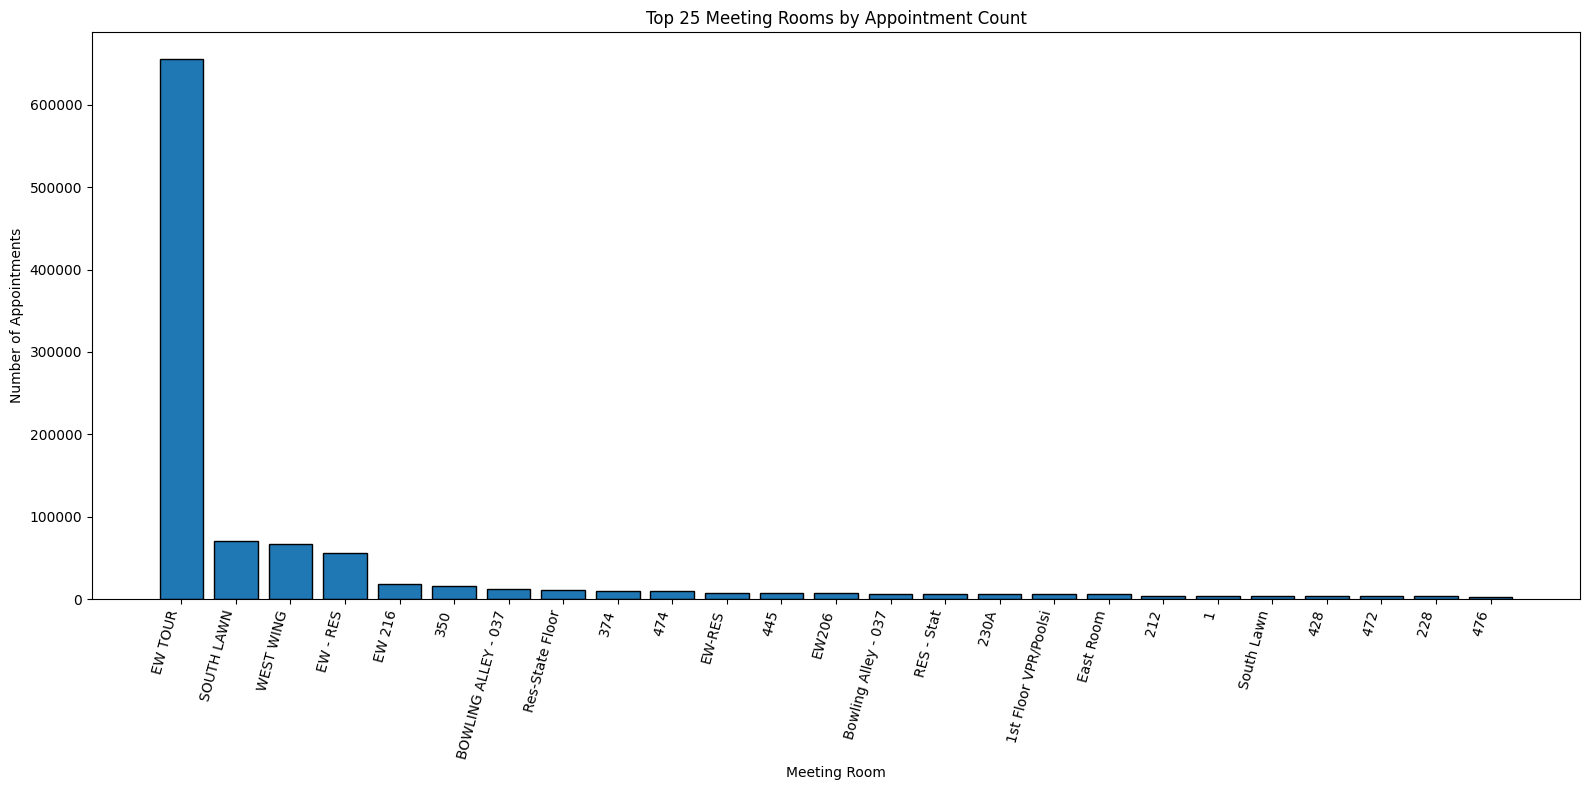

In [23]:
# Bar chart: Meeting Room (x) vs Count of Appointments (y)
valid = merged_df.dropna(subset=['appointment_start_date', 'meeting_room'])
counts = valid.groupby(valid['meeting_room'].str.strip()).size().sort_values(ascending=False)

top_n = 25  # adjust if you want more/less categories
to_plot = counts.head(top_n)

plt.figure(figsize=(16,8))
plt.bar(to_plot.index, to_plot.values, edgecolor='black')
plt.xlabel('Meeting Room')
plt.ylabel('Number of Appointments')
plt.title(f'Top {top_n} Meeting Rooms by Appointment Count')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

In [29]:
merged_df_without_na = merged_df[merged_df['appointment_start_date'] != 'NaT']

In [30]:
merged_df_without_na

,last_name,first_name,appointment_start_date,total_people,meeting_room
0,BARRIGA,SEBASTIAN,2021-04-01,1.0,3025
1,BROOKS,ROBIN,2021-04-01,1.0,393
2,CULLEN,REBECCA,2021-04-01,1.0,422
3,CULLEN,REBECCA,2021-04-01,1.0,422
4,BARAN,THEODORE,2021-04-01,2.0,234
...,...,...,...,...,...
1184410,LEACH,NIA,2023-12-30,6.0,187
1184411,KOH,JOHN,2023-12-30,12.0,BOWLING ALLEY - 037
1184412,JOHNSON,MATTISON,2023-12-30,6.0,WEST WING
1184413,KOH,HOWARD,2023-12-30,12.0,BOWLING ALLEY - 037


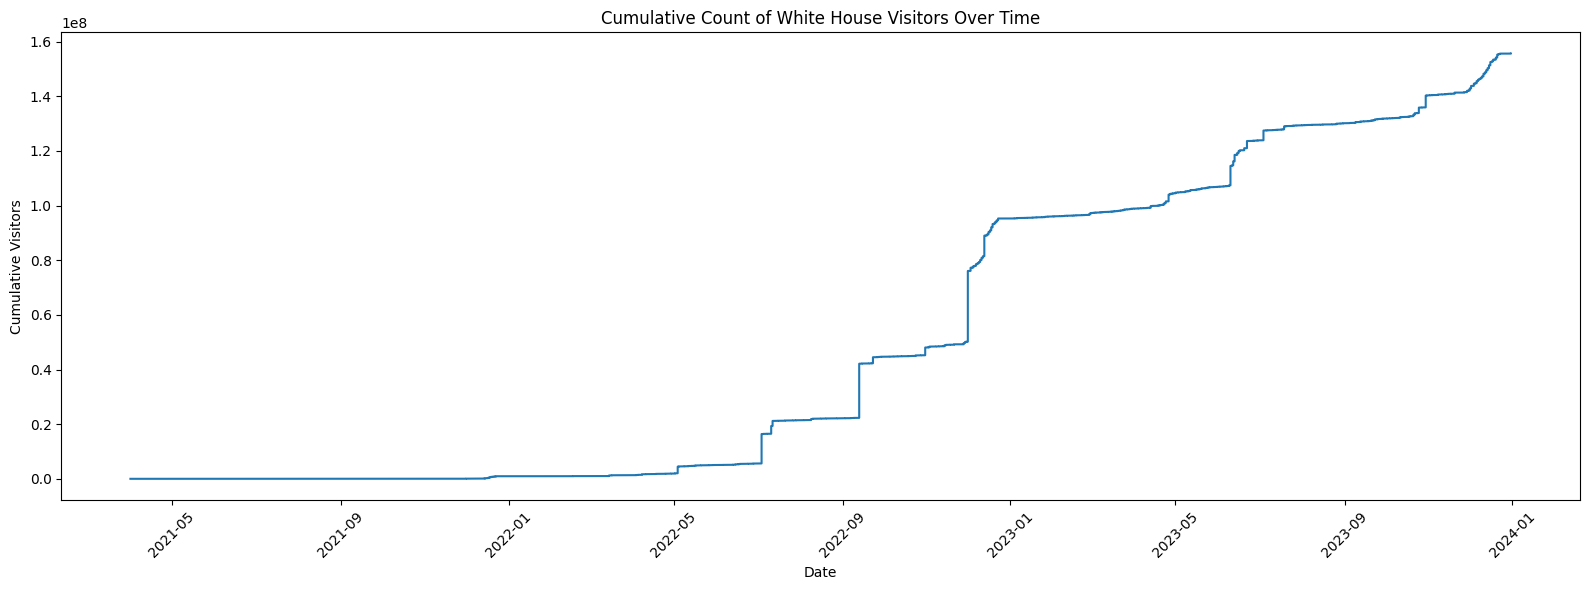

In [32]:
# Step chart: Cumulative count of visitors over time
appointment_dates = pd.to_datetime(merged_df_without_na['appointment_start_date'], errors='coerce')
cumulative_visitors = merged_df_without_na.groupby(appointment_dates.dt.date)['total_people'].sum().cumsum()

plt.figure(figsize=(16,6))
plt.step(cumulative_visitors.index, cumulative_visitors.values, where='post')
plt.xlabel('Date')
plt.ylabel('Cumulative Visitors')
plt.title('Cumulative Count of White House Visitors Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

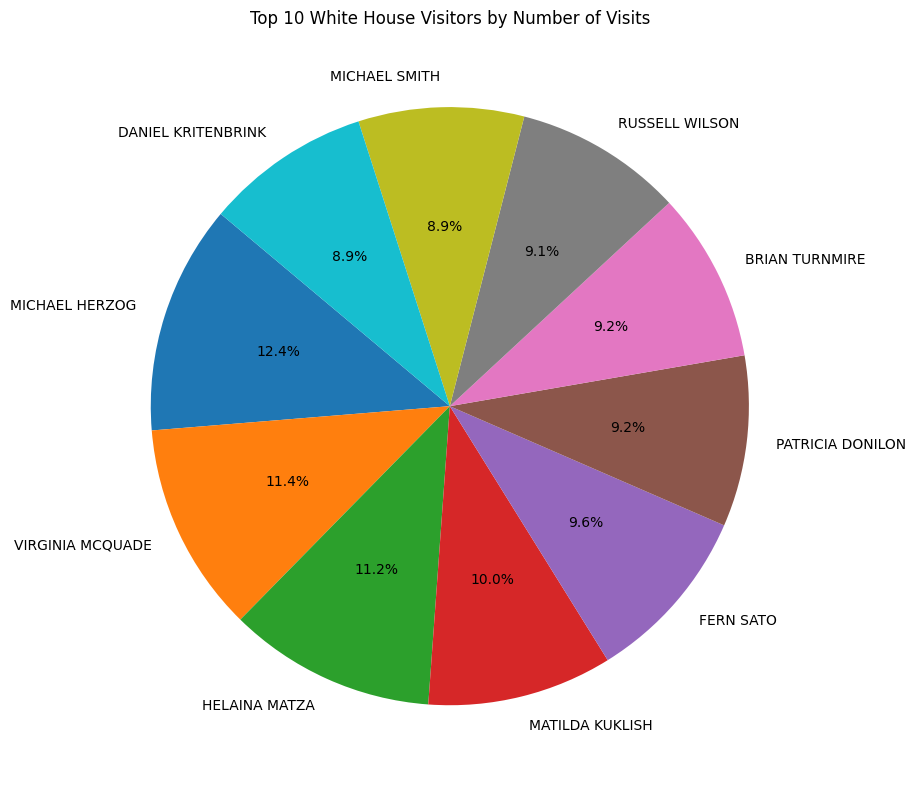

In [24]:
# Group by unique visitor (first_name + last_name), count visits
visitor_counts = valid.groupby(['first_name', 'last_name']).size().sort_values(ascending=False)

# Get top 10 visitors
top_10_visitors = visitor_counts.head(10)

# Prepare labels for pie chart
labels = [f"{fn} {ln}" for fn, ln in top_10_visitors.index]

plt.figure(figsize=(10, 8))
plt.pie(top_10_visitors, labels=labels, autopct='%1.1f%%', startangle=140)
plt.title('Top 10 White House Visitors by Number of Visits')
plt.tight_layout()
plt.show()

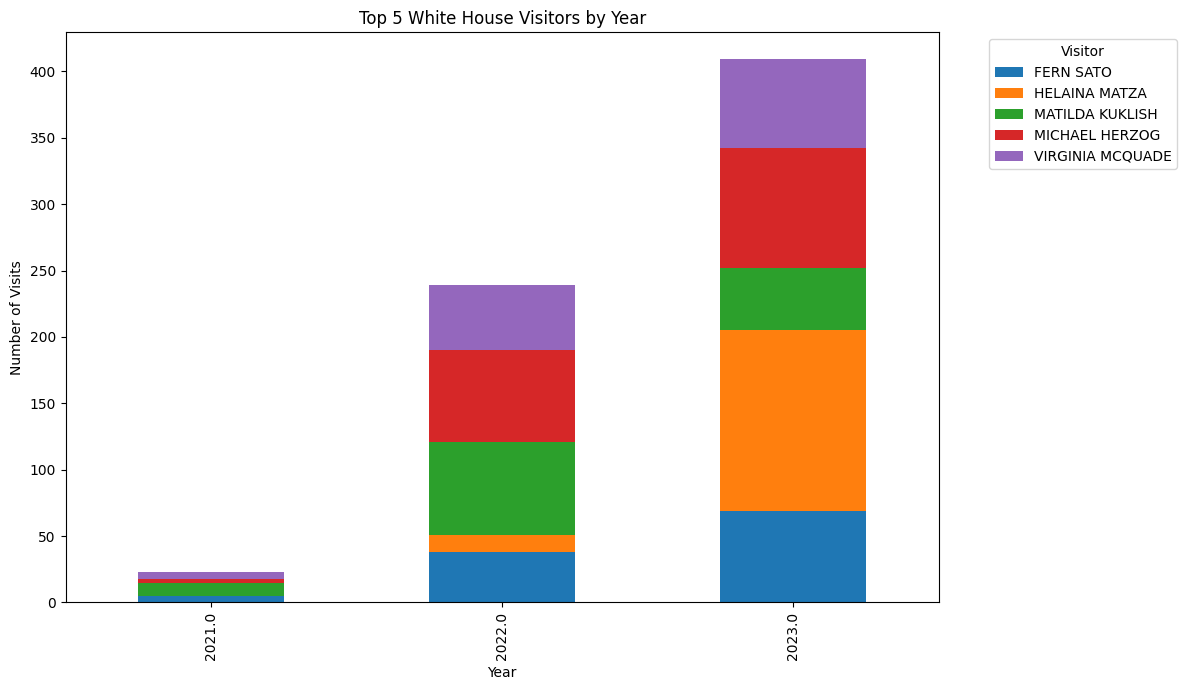

In [25]:
# Extract year from appointment_start_date
valid['year'] = pd.to_datetime(valid['appointment_start_date'], errors='coerce').dt.year

# Get top 5 visitors overall
top_5 = visitor_counts.head(5)
top_5_names = set(top_5.index)

# Create a new column for visitor name
valid['visitor_name'] = valid['first_name'].str.strip() + ' ' + valid['last_name'].str.strip()

# Filter for only top 5 visitors
valid_top5 = valid[valid.set_index(['first_name', 'last_name']).index.isin(top_5_names)]

# Group by year and visitor_name, count rows
grouped = valid_top5.groupby(['year', 'visitor_name']).size().unstack(fill_value=0)

# Plot stacked bar chart
grouped.plot(kind='bar', stacked=True, figsize=(12,7))
plt.xlabel('Year')
plt.ylabel('Number of Visits')
plt.title('Top 5 White House Visitors by Year')
plt.legend(title='Visitor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### The transparency of the visits allows us to see the trend of visitors over times. This is the visitors to the White House from 2021 to 2023.